# 01 - Understanding the data: Sri Lankan telco customer churn

**Problem (local):** Sri Lankan mobile operators lose customers to competitors every month. Winning a new customer costs more than keeping an existing one, so an operator wants to spot customers who are **likely to leave (churn)** early enough to offer them something.

**Dataset:** *Real World Customer Churn Dataset in Telco Domain* (Kaggle, Lasal Jayawardena, CC0). Anonymised usage of **65,005 customers** of one of the largest telcos in Sri Lanka, 1 January to 31 March 2023 (90 days). Spending is in LKR, and it includes local apps such as **Helakuru**.

This notebook answers: what is in the data, what does each column mean, is it clean, how do churners behave, and **which part of the data is safe to use** (leakage check).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys
sys.path.insert(0, "../src")
from features import USAGE_TYPES, WINDOWS, RAW_FEATURES, build_features
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110})
feats = pd.read_csv("../data/raw/customer_first30.csv")
train = pd.read_csv("../data/raw/train_cxid.csv"); test = pd.read_csv("../data/raw/test_cxid.csv")
df = pd.concat([train.assign(split="train"), test.assign(split="test")]).merge(feats, on="customer_id")
print("Customers:", len(df), "| train:", len(train), "| test:", len(test))
df.head(3)

Customers: 65005 | train: 52004 | test: 13001


,customer_id,churn,split,app_facebook_active,app_facebook_d01_10,app_facebook_d11_20,app_facebook_d21_30,app_helakuru_active,app_helakuru_d01_10,app_helakuru_d11_20,...,voice_d2d_outgoing_d11_20,voice_d2d_outgoing_d21_30,voice_d2nd_outgoing_active,voice_d2nd_outgoing_d01_10,voice_d2nd_outgoing_d11_20,voice_d2nd_outgoing_d21_30,voice_nd2d_incoming_active,voice_nd2d_incoming_d01_10,voice_nd2d_incoming_d11_20,voice_nd2d_incoming_d21_30
0,a8cfed4379972f41e730a31a5c500e9ed2592374761b09...,0,train,16.0,106.289,157.041,61.922,16.0,5.191,3.468,...,27.408,25.225,20.0,15.545,8.972,21.591,24.0,21.452,24.559,10.846
1,d231e6c6dfd09290c16f640288edcd0ec5de526681c5e8...,0,train,18.0,187.574,115.076,132.528,10.0,2.453,7.554,...,14.846,20.287,22.0,20.967,10.798,26.786,20.0,21.264,8.177,30.521
2,787d994dc6e133f5711414ac7959d3263af560f19dd634...,0,train,27.0,144.728,112.303,102.901,22.0,12.484,6.909,...,32.717,6.526,20.0,38.551,26.110,43.767,17.0,21.828,12.481,8.892


## 1. What each column means

The original file has **one row per customer per usage type** and 90 daily values. There are 12 usage types:

| Group | Usage type | Unit (from the dataset description) |
|---|---|---|
| Apps | Facebook, TikTok, YouTube, WhatsApp, **Helakuru**, other apps | MB of data per day |
| Packs | Data packs, value-added services (VAS) | LKR spent per day |
| Calls | Outgoing and incoming, same network (d2d) and other networks (d2nd / nd2d) | Minutes per day |

From the first 30 days we build, for every usage type: the **average per day in days 1-10, 11-20 and 21-30**, and the number of **active days**. That gives 48 raw columns. The label `churn` is 1 if the customer left, 0 if they stayed.

In [2]:
print("Missing values      :", int(df[RAW_FEATURES].isna().sum().sum()))
print("Duplicate customers :", int(df["customer_id"].duplicated().sum()))
print("Negative values     :", int((df[RAW_FEATURES] < 0).sum().sum()))
print("In both train & test:", len(set(train.customer_id) & set(test.customer_id)))
summary = df[[f"{u}_d01_10" for u in USAGE_TYPES]].describe().T[["mean", "50%", "max"]].round(1)
summary.index = [USAGE_TYPES[i.replace("_d01_10", "")] for i in summary.index]
summary

Missing values      : 0
Duplicate customers : 0
Negative values     : 0
In both train & test: 0


,mean,50%,max
Facebook data (MB per day),86.1,76.8,512.4
TikTok data (MB per day),74.8,66.6,378.1
YouTube data (MB per day),137.7,122.9,757.0
WhatsApp data (MB per day),11.5,10.3,60.6
Helakuru app data (MB per day),11.5,10.2,60.0
Other apps data (MB per day),114.8,102.6,726.7
Spend on data packs (LKR per day),115.1,102.7,614.9
Spend on value-added services (LKR per day),22.9,20.5,136.3
"Outgoing calls, same network (min per day)",23.0,20.5,134.3
"Outgoing calls, other networks (min per day)",22.9,20.5,123.3


The data is **clean**: no missing values, no duplicates, no negative values, and no customer appears in both the train and the test set. Imputation is still kept inside the model pipeline (median), so a blank value from the app cannot break the model.

The usage columns are **right-skewed**: the mean is above the median and a few heavy users are far above everyone else (see the max column). This matters for Logistic Regression, so it gets a log transform and scaling; tree models do not need it.

## 2. Class balance

        mean   size
split              
test   0.229  13001
train  0.231  52004


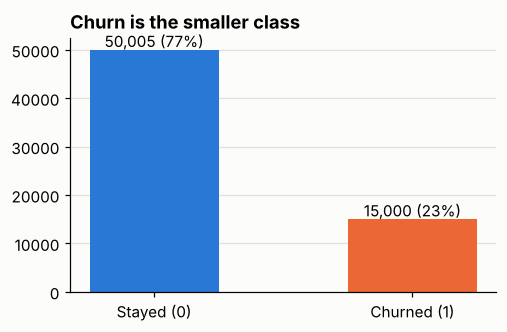

In [3]:
rate = df.groupby("split")["churn"].agg(["mean", "size"]); print(rate.round(3))
fig, ax = plt.subplots(figsize=(5, 3))
counts = df["churn"].value_counts().sort_index()
ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=[BLUE, ORANGE], width=0.5)
for i, v in enumerate(counts.values): ax.text(i, v + 600, f"{v:,} ({v/len(df):.0%})", ha="center")
ax.set_title("Churn is the smaller class"); ax.grid(axis="x", visible=False); plt.show()

About **23%** of customers churn. The classes are imbalanced, so **accuracy is misleading**: a model that always says "stays" is 77% accurate and finds no churners. We therefore judge models by **F1, recall and PR-AUC for the churn class**, and use class weights during training.

## 3. LEAKAGE CHECK: which days can we use?

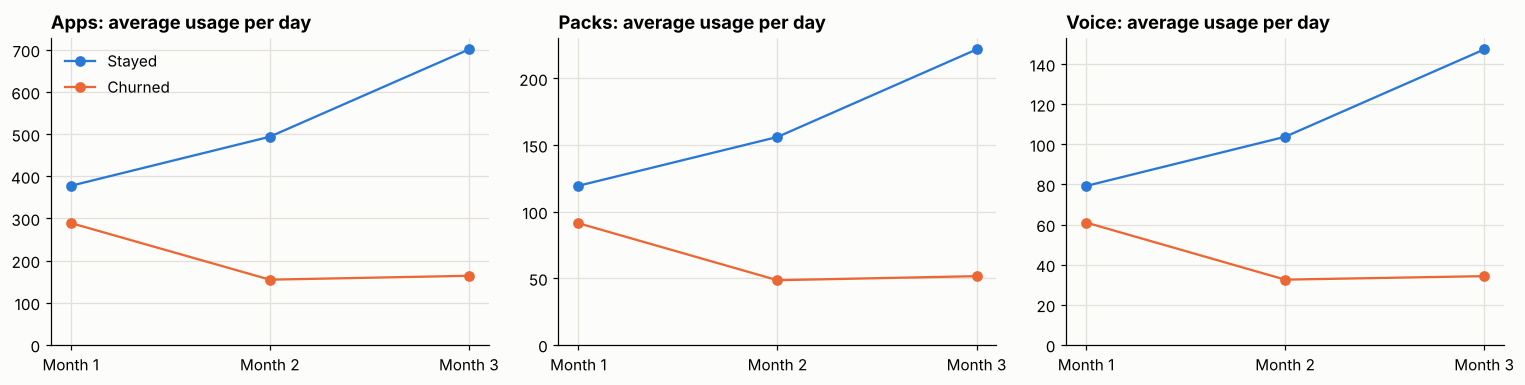

churn                            0      1
days_since_any_use_at_day90              
1.0                          50005  14034
2.0                              0    606
3.0                              0    199
4.0                              0     68
5.0                              0     27
6.0                              0     28
7.0                              0     10
8.0                              0     28


In [4]:
m = pd.read_csv("../data/raw/monthly_usage_check.csv").merge(pd.concat([train, test]), on="customer_id")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, g in zip(axes, ["apps", "packs", "voice"]):
    for label, colour, name in [(0, BLUE, "Stayed"), (1, ORANGE, "Churned")]:
        vals = m[m.churn == label][[f"{g}_month1", f"{g}_month2", f"{g}_month3"]].mean()
        ax.plot(["Month 1", "Month 2", "Month 3"], vals.values, marker="o", color=colour, label=name)
    ax.set_title(f"{g.capitalize()}: average usage per day"); ax.set_ylim(0, None)
axes[0].legend(); plt.tight_layout(); plt.show()
print(pd.crosstab(m["days_since_any_use_at_day90"].clip(upper=8), m["churn"]))

**This is the most important finding about the data.**

- In months 2 and 3 the two groups move in **opposite directions**: churners' usage roughly halves, while customers who stayed use more and more. The gap becomes huge.
- A model given days 1-60 or all 90 days reaches **ROC-AUC 1.000**: it simply sees that the customer has already stopped using the service. That is like predicting exam results while looking at the results sheet. By then the customer has effectively left; there is nothing to predict and no time to act.
- This is called **leakage**: information about the answer leaks into the inputs.

**Decision:** use only the **first 30 days**. The question becomes: *from a customer's first month, can we tell that they will leave later?* That is a real early-warning problem, and the operator still has time to offer a retention package.

## 4. How churners behave in the first month

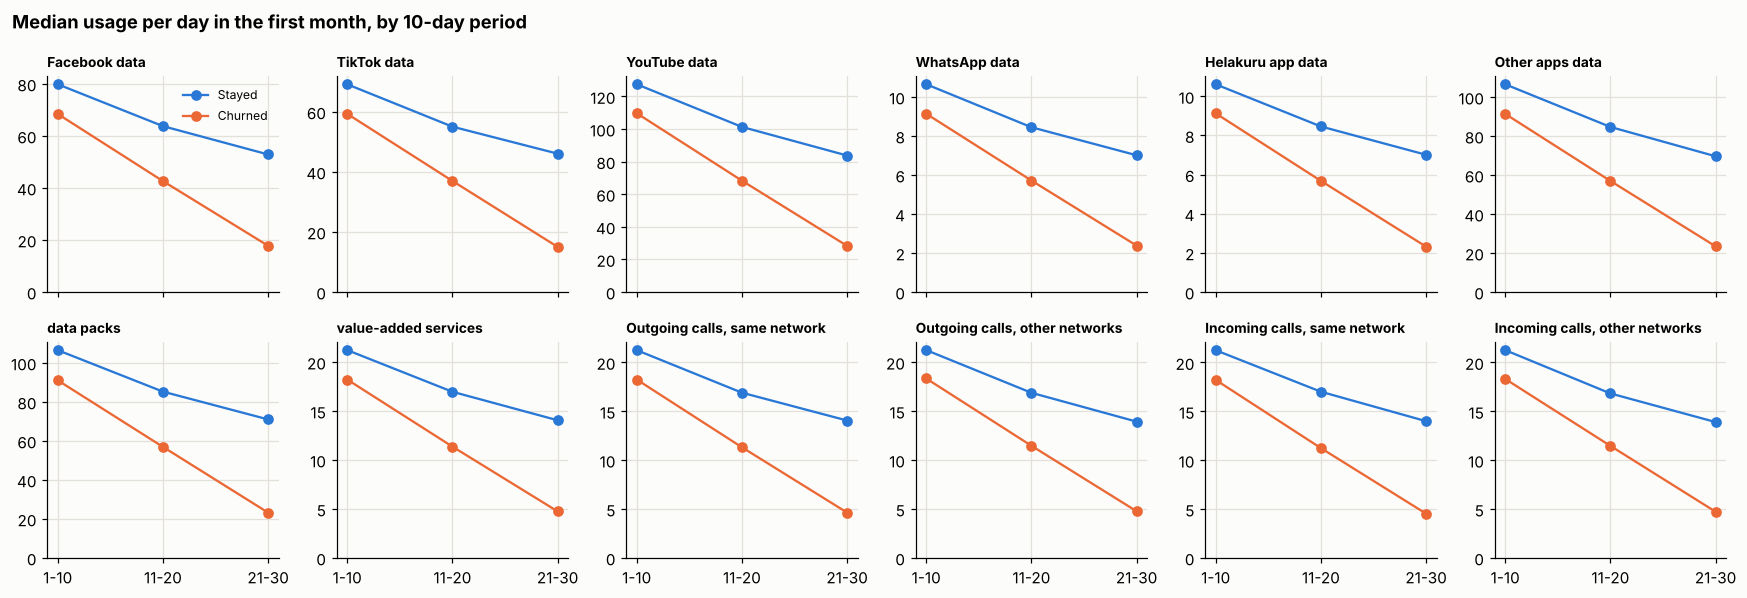

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5), sharex=True)
for ax, u in zip(axes.ravel(), USAGE_TYPES):
    for label, colour in [(0, BLUE), (1, ORANGE)]:
        ax.plot(["1-10", "11-20", "21-30"], df[df.churn == label][[f"{u}_{w}" for w in WINDOWS]].median().values,
                marker="o", color=colour)
    ax.set_title(USAGE_TYPES[u].split(" (")[0].replace("Spend on ", ""), fontsize=9); ax.set_ylim(0, None)
axes[0, 0].legend(["Stayed", "Churned"], fontsize=8)
fig.suptitle("Median usage per day in the first month, by 10-day period", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [6]:
eng = build_features(df)
ratio_cols = ["apps_ratio", "packs_ratio", "voice_ratio"]
print(eng.assign(churn=df.churn.values).groupby("churn")[ratio_cols].median().round(2))

       apps_ratio  packs_ratio  voice_ratio
churn                                      
0            0.70         0.66         0.70
1            0.38         0.30         0.39


Already inside the first month, churners use **less, and less each 10 days**. Their usage at the end of the month is a smaller share of their usage at the start (the `ratio` features), for apps, packs and calls. This is why the feature engineering adds, for each usage type and group, the **change** and the **end/start ratio** between days 1-10 and days 21-30.

## 5. Summary

1. 65,005 real anonymised Sri Lankan customers, 12 usage types, given train/test split, 23% churn.
2. Clean: no missing values, duplicates or negative values. Usage is right-skewed.
3. **Leakage found and removed**: later days reveal churn directly, so only days 1-30 are used.
4. Churners show a **declining first month** in every usage group, which the engineered features capture.
5. Imbalanced classes: models are judged by F1 / recall / PR-AUC for churn, with class weights.

**Limitations of the data (important for interpreting the results):**
- The separation between churners and stayers is unusually clean for real telco data.
- Several usage types have almost identical averages (all four call types and VAS spend average about 22.9 per day), and customers who stayed show a rise in month 3. Real usage would not look this regular. The author describes the data as real and anonymised, but the values were very likely rescaled or partly generated during anonymisation.
- So the results show how well the methods work on this dataset; a live operator system would probably score lower.